# BlinkIT Grocery Sales Analysis

**Sapphire IQ | Student Project | Retail and Grocery Sales Analytics**

Prepared by Pradip

Each row in `BlinkIT Grocery Data.xlsx` is one product listed at one outlet. The analysis follows the four project objectives:

1. Understand the business and its sales performance.
2. Make sure the available information is reliable.
3. Find out what is driving better sales performance.
4. Help management make better business decisions.

Tools: Python, Pandas, NumPy, Matplotlib, and Seaborn.

## Setup

In [1]:
%matplotlib inline

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.titleweight"] = "semibold"
plt.rcParams["axes.labelsize"] = 11

COLORS = ["#1B4F72", "#148F77", "#B7950B", "#CA6F1E", "#1A5276", "#117A65", "#6C3483", "#922B21"]
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

DATA_PATH = Path("BlinkIT Grocery Data.xlsx")
if not DATA_PATH.exists():
    raise FileNotFoundError("BlinkIT Grocery Data.xlsx must sit in the same folder as this notebook.")


def show_figure(name):
    """Save the current figure and display it in the notebook."""
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=140, bbox_inches="tight")
    plt.show()


raw = pd.read_excel(DATA_PATH, sheet_name="BlinkIT Grocery Data")
print(f"Rows: {len(raw):,}")
print(f"Columns: {raw.shape[1]}")
raw.head()

Rows: 8,523
Columns: 12


,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.100014,15.10,145.4786,5.0
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.008596,11.80,115.3492,5.0
2,Regular,FDR28,Frozen Foods,2016,OUT046,Tier 1,Small,Supermarket Type1,0.025896,13.85,165.0210,5.0
3,Regular,FDL50,Canned,2014,OUT013,Tier 3,High,Supermarket Type1,0.042278,12.15,126.5046,5.0
4,Low Fat,DRI25,Soft Drinks,2015,OUT045,Tier 2,Small,Supermarket Type1,0.033970,19.60,55.1614,5.0


## Objective 1. Understand the business and its sales performance

The first pass uses the file as it was received, before any corrections.

### Task 1.1. What types of products is BlinkIT selling?

BlinkIT sells 16 grocery and household categories. The catalog is led by fresh and packaged food: Fruits and Vegetables, Snack Foods, Household, Frozen Foods, and Dairy. A smaller set of categories (Seafood, Breakfast, Starchy Foods) has very few listings.

Column guide


,Column,Meaning
0,Item Fat Content,Fat label recorded for the product
1,Item Identifier,Product code
2,Item Type,Product category
3,Outlet Establishment Year,Year the outlet opened
4,Outlet Identifier,Outlet code
5,Outlet Location Type,City tier of the outlet
6,Outlet Size,Recorded outlet size
7,Outlet Type,Outlet format
8,Item Visibility,Share of shelf display allocated to the product
9,Item Weight,Product weight


Distinct products: 1,559
Product categories: 16

Listings by category


,Listings
Item Type,
Fruits and Vegetables,1232
Snack Foods,1200
Household,910
Frozen Foods,856
Dairy,682
Canned,649
Baking Goods,648
Health and Hygiene,520
Soft Drinks,445


findfont: Failed to find font weight semibold, now using 700.


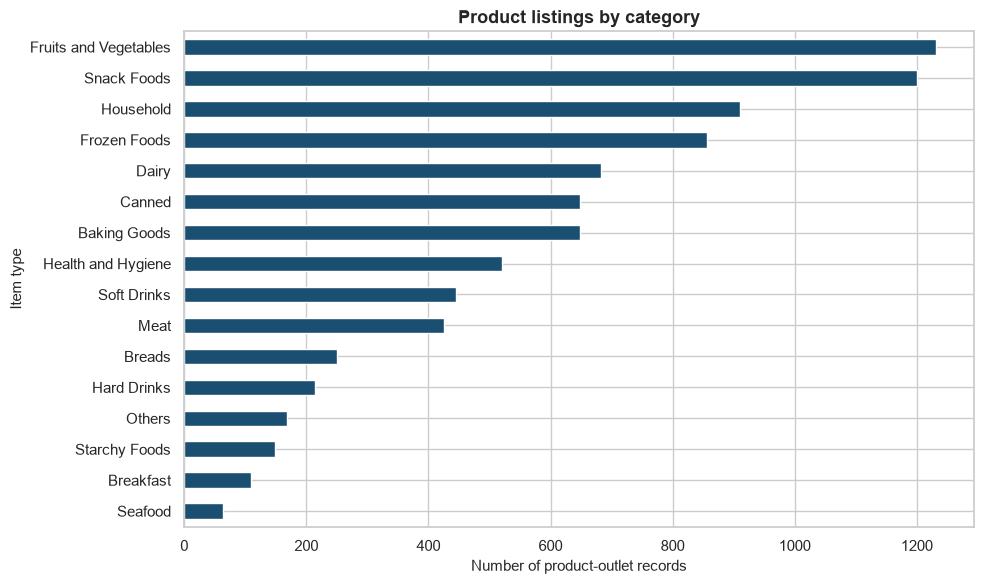


Fat labels as stored in the file


,Records
Item Fat Content,
Low Fat,5089
Regular,2889
LF,316
reg,117
low fat,112


In [2]:
print("Column guide")
display(pd.DataFrame({
    "Column": raw.columns,
    "Meaning": [
        "Fat label recorded for the product",
        "Product code",
        "Product category",
        "Year the outlet opened",
        "Outlet code",
        "City tier of the outlet",
        "Recorded outlet size",
        "Outlet format",
        "Share of shelf display allocated to the product",
        "Product weight",
        "Sales value of the product at that outlet",
        "Customer rating of the product at that outlet",
    ],
}))

item_counts = raw["Item Type"].value_counts().sort_values(ascending=True)
print(f"Distinct products: {raw['Item Identifier'].nunique():,}")
print(f"Product categories: {raw['Item Type'].nunique()}")
print("\nListings by category")
display(item_counts.sort_values(ascending=False).to_frame("Listings"))

fig, ax = plt.subplots(figsize=(10, 6))
item_counts.plot(kind="barh", color="#1B4F72", ax=ax)
ax.set_title("Product listings by category")
ax.set_xlabel("Number of product-outlet records")
ax.set_ylabel("Item type")
show_figure("01_listings_by_category")

print("\nFat labels as stored in the file")
display(raw["Item Fat Content"].value_counts().to_frame("Records"))

Low Fat and Regular are the two real fat groups, but the file also stores `LF`, `low fat`, and `reg`. Those labels are the same ideas written in different ways. That is corrected in Objective 2 before any fat comparison.

Household, Health and Hygiene, and Others are non-food categories. A fat label is not a useful description for those products, so they are separated from the food comparison later.

### Task 1.2. What types of outlets does BlinkIT operate, and where?

There are 10 outlets. Six are Supermarket Type1. There is one Supermarket Type2, one Supermarket Type3, and two Grocery Stores. Outlets sit in three city tiers. Establishment years run from 2011 to 2022.

,Outlet Identifier,Outlet Type,Outlet Location Type,Outlet Establishment Year,Records,Size_labels,Sizes_recorded
0,OUT010,Grocery Store,Tier 3,2011,555,3,"High, Medium, Small"
1,OUT013,Supermarket Type1,Tier 3,2014,932,1,High
2,OUT017,Supermarket Type1,Tier 2,2020,926,3,"High, Medium, Small"
3,OUT018,Supermarket Type2,Tier 3,2022,928,1,Medium
4,OUT019,Grocery Store,Tier 1,2018,528,1,Small
5,OUT027,Supermarket Type3,Tier 3,2018,935,1,Medium
6,OUT035,Supermarket Type1,Tier 2,2017,930,1,Small
7,OUT045,Supermarket Type1,Tier 2,2015,929,3,"High, Medium, Small"
8,OUT046,Supermarket Type1,Tier 1,2016,930,1,Small
9,OUT049,Supermarket Type1,Tier 1,2012,930,1,Medium


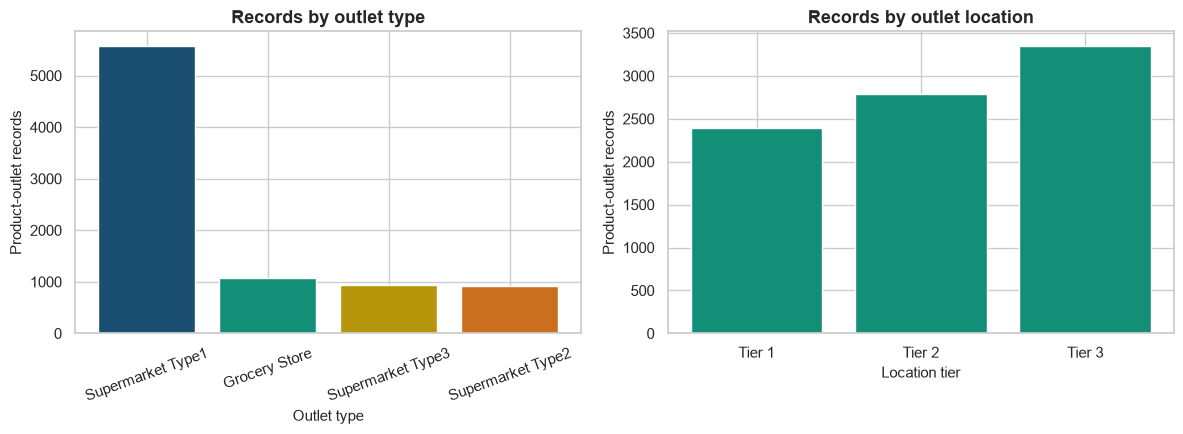

Outlet size labels on the raw file


,Records
Outlet Size,
Medium,3631
Small,3139
High,1753


Outlets whose size label is not the same on every row: 3


In [3]:
outlet_profile = (
    raw.groupby(
        ["Outlet Identifier", "Outlet Type", "Outlet Location Type", "Outlet Establishment Year"],
        as_index=False,
    )
    .agg(
        Records=("Sales", "size"),
        Size_labels=("Outlet Size", "nunique"),
        Sizes_recorded=("Outlet Size", lambda s: ", ".join(sorted(s.unique()))),
    )
    .sort_values("Outlet Identifier")
)
display(outlet_profile)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
type_counts = raw["Outlet Type"].value_counts()
loc_counts = raw["Outlet Location Type"].value_counts().sort_index()
axes[0].bar(type_counts.index, type_counts.values, color=COLORS[: len(type_counts)])
axes[0].set_title("Records by outlet type")
axes[0].set_xlabel("Outlet type")
axes[0].set_ylabel("Product-outlet records")
axes[0].tick_params(axis="x", rotation=20)
axes[1].bar(loc_counts.index, loc_counts.values, color="#148F77")
axes[1].set_title("Records by outlet location")
axes[1].set_xlabel("Location tier")
axes[1].set_ylabel("Product-outlet records")
show_figure("02_outlets_by_type_and_location")

print("Outlet size labels on the raw file")
display(raw["Outlet Size"].value_counts().to_frame("Records"))
print(
    "Outlets whose size label is not the same on every row:",
    int((outlet_profile["Size_labels"] > 1).sum()),
)

Three outlets (OUT010, OUT017, and OUT045) are recorded as High, Medium, and Small at the same time. An outlet has one size, so those labels cannot be compared until they are reconciled. The other seven outlets have a single size each.

### Task 1.3. How much is BlinkIT selling overall?

Total sales in the file are the sum of the Sales column across every product-outlet row. The same product appears at several outlets, and its Sales value barely moves from one outlet to another. Outlet totals therefore differ mainly because some outlets list more products.

,Measure,Value
0,Product-outlet records,"8,523"
1,Distinct products,"1,559"
2,Outlets,10
3,Total sales,"1,201,681.49"
4,Average sales per record,140.99
5,Median sales per record,143.01
6,Lowest sales value,31.29
7,Highest sales value,266.89
8,Typical gap in Sales for the same product acro...,2.90


C:\Users\pradi\AppData\Local\Temp\ipykernel_28140\845734459.py:38: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1].boxplot(raw["Sales"], vert=True, patch_artist=True, boxprops={"facecolor": "#D4E6F1"})


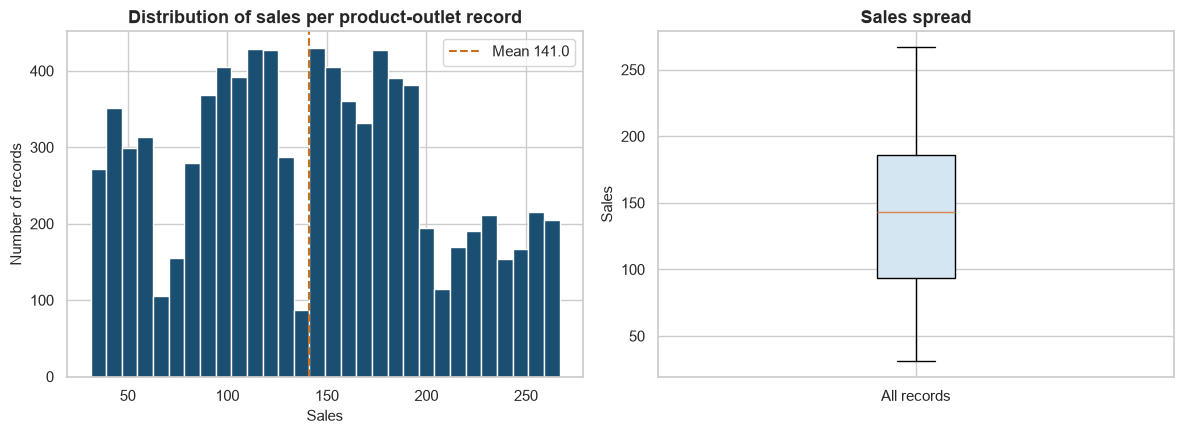

In [4]:
same_item = raw.groupby("Item Identifier")["Sales"].agg(min_sales="min", max_sales="max", listings="size")
same_item["gap"] = same_item["max_sales"] - same_item["min_sales"]
multi = same_item[same_item["listings"] > 1]

summary = pd.DataFrame({
    "Measure": [
        "Product-outlet records",
        "Distinct products",
        "Outlets",
        "Total sales",
        "Average sales per record",
        "Median sales per record",
        "Lowest sales value",
        "Highest sales value",
        "Typical gap in Sales for the same product across outlets",
    ],
    "Value": [
        f"{len(raw):,}",
        f"{raw['Item Identifier'].nunique():,}",
        f"{raw['Outlet Identifier'].nunique():,}",
        f"{raw['Sales'].sum():,.2f}",
        f"{raw['Sales'].mean():,.2f}",
        f"{raw['Sales'].median():,.2f}",
        f"{raw['Sales'].min():,.2f}",
        f"{raw['Sales'].max():,.2f}",
        f"{multi['gap'].median():,.2f}",
    ],
})
display(summary)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hist(raw["Sales"], bins=30, color="#1B4F72", edgecolor="white")
axes[0].axvline(raw["Sales"].mean(), color="#CA6F1E", linestyle="--", label=f"Mean {raw['Sales'].mean():.1f}")
axes[0].set_title("Distribution of sales per product-outlet record")
axes[0].set_xlabel("Sales")
axes[0].set_ylabel("Number of records")
axes[0].legend()
axes[1].boxplot(raw["Sales"], vert=True, patch_artist=True, boxprops={"facecolor": "#D4E6F1"})
axes[1].set_title("Sales spread")
axes[1].set_ylabel("Sales")
axes[1].set_xticks([1])
axes[1].set_xticklabels(["All records"])
show_figure("03_sales_distribution")

Sales values run from about 31 to 267, with the middle of the catalog near 141. There is no separate quantity column, so this figure is the sales value stored on each row, not a unit count. Because the same product keeps almost the same sales value everywhere it is listed, category mix and catalog size are the levers that change total sales. A higher price-like sales value on the product itself is what separates one item from another.

### Task 1.4. What do customer ratings and product performance look like?

The average rating is just under 4 out of 5. Most records sit in a narrow band around 4. A thin tail of very low ratings needs a quality check, but it is a small share of the file.

,Measure,Value
0,Average rating,3.97
1,Median rating,4.00
2,Minimum,1.0
3,Maximum,5.0
4,Records rated below 3,424 (5.0%)
5,Records rated 1.0,114


,Records,Average_rating,Average_sales
Item Type,,,
Meat,425,4.02,139.88
Household,910,4.00,149.42
Canned,649,3.99,139.76
Health and Hygiene,520,3.99,130.82
Baking Goods,648,3.98,126.38
Frozen Foods,856,3.97,138.50
Dairy,682,3.97,148.50
Seafood,64,3.96,141.84
Fruits and Vegetables,1232,3.96,144.58


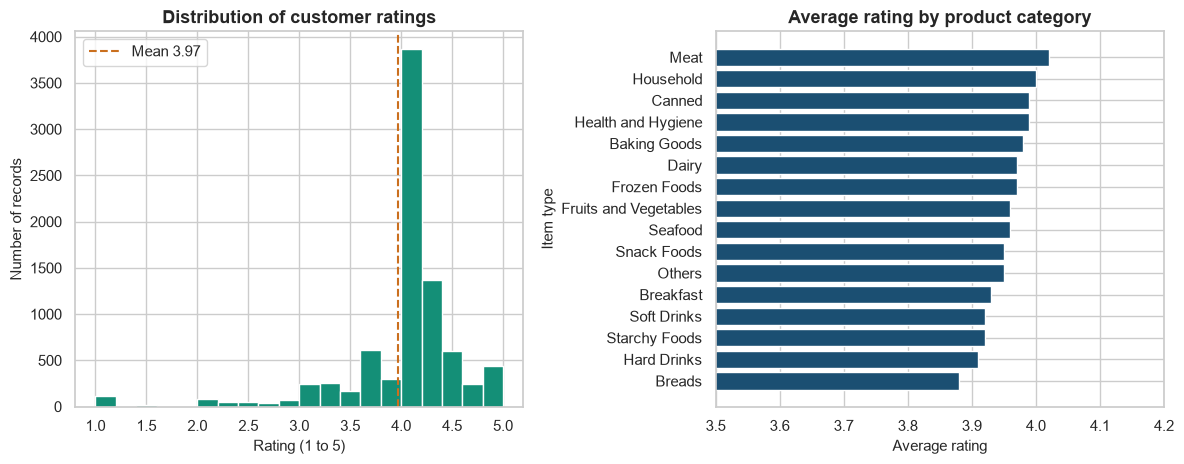

In [5]:
rating_summary = pd.DataFrame({
    "Measure": ["Average rating", "Median rating", "Minimum", "Maximum", "Records rated below 3", "Records rated 1.0"],
    "Value": [
        f"{raw['Rating'].mean():.2f}",
        f"{raw['Rating'].median():.2f}",
        f"{raw['Rating'].min():.1f}",
        f"{raw['Rating'].max():.1f}",
        f"{(raw['Rating'] < 3).sum():,} ({(raw['Rating'] < 3).mean():.1%})",
        f"{(raw['Rating'] == 1).sum():,}",
    ],
})
display(rating_summary)

rating_by_type = (
    raw.groupby("Item Type")
    .agg(Records=("Rating", "size"), Average_rating=("Rating", "mean"), Average_sales=("Sales", "mean"))
    .sort_values("Average_rating", ascending=False)
    .round(2)
)
display(rating_by_type)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
axes[0].hist(raw["Rating"], bins=20, color="#148F77", edgecolor="white")
axes[0].axvline(raw["Rating"].mean(), color="#CA6F1E", linestyle="--", label=f"Mean {raw['Rating'].mean():.2f}")
axes[0].set_title("Distribution of customer ratings")
axes[0].set_xlabel("Rating (1 to 5)")
axes[0].set_ylabel("Number of records")
axes[0].legend()
order = rating_by_type.sort_values("Average_rating").index
axes[1].barh(order, rating_by_type.loc[order, "Average_rating"], color="#1B4F72")
axes[1].set_xlim(3.5, 4.2)
axes[1].set_title("Average rating by product category")
axes[1].set_xlabel("Average rating")
axes[1].set_ylabel("Item type")
show_figure("04_ratings")

Ratings barely differ by category. Meat is the highest on average and Breads the lowest, but every category is still close to 4. Rating is not yet a signal of which categories sell more. That link is tested directly in Objective 3, after the file is cleaned.

## Objective 2. Make sure the available information is reliable

Four checks: missing values, repeated records, unusual values, and labels that mean the same thing but are written differently.

### Task 2.1. What information is missing?

,Missing_rows,Missing_pct
Item Fat Content,0,0.00
Item Identifier,0,0.00
Item Type,0,0.00
Outlet Establishment Year,0,0.00
Outlet Identifier,0,0.00
Outlet Location Type,0,0.00
Outlet Size,0,0.00
Outlet Type,0,0.00
Item Visibility,0,0.00
Item Weight,1463,17.17


,Missing_weight,Records
Outlet Identifier,,
OUT010,0,555
OUT013,0,932
OUT017,0,926
OUT018,0,928
OUT019,528,528
OUT027,935,935
OUT035,0,930
OUT045,0,929
OUT046,0,930


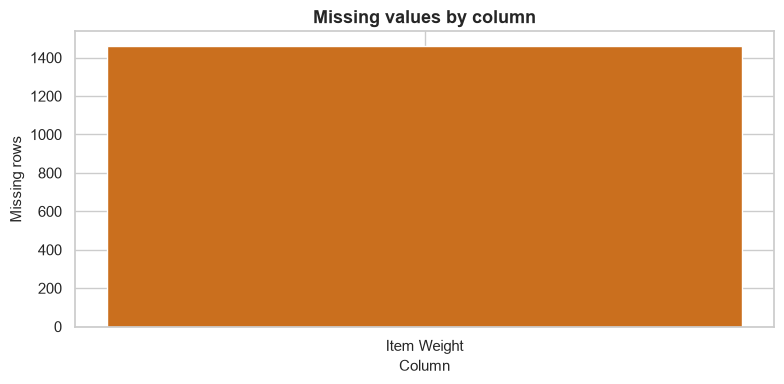

In [6]:
missing = raw.isna().sum().rename("Missing_rows").to_frame()
missing["Missing_pct"] = (missing["Missing_rows"] / len(raw) * 100).round(2)
display(missing)

weight_gap = (
    raw.groupby("Outlet Identifier")["Item Weight"]
    .apply(lambda s: int(s.isna().sum()))
    .rename("Missing_weight")
    .to_frame()
)
weight_gap["Records"] = raw.groupby("Outlet Identifier").size()
display(weight_gap)

fig, ax = plt.subplots(figsize=(8, 4))
present = missing["Missing_rows"]
present = present[present > 0]
ax.bar(present.index, present.values, color="#CA6F1E")
ax.set_title("Missing values by column")
ax.set_xlabel("Column")
ax.set_ylabel("Missing rows")
show_figure("05_missing_values")

Item Weight is the only column with blank cells: 1,463 rows, about 17% of the file. The blanks are not spread across the business. Every weight is missing at OUT019 and OUT027, and nowhere else. Weight is a property of the product, and the same product has a weight at the other outlets, so those blanks can be filled from the product's own known weight.

### Task 2.2. What information has been repeated?

In [7]:
dup_report = pd.DataFrame({
    "Check": [
        "Fully identical rows",
        "Same product listed twice at the same outlet",
        "Products listed at more than one outlet",
    ],
    "Count": [
        int(raw.duplicated().sum()),
        int(raw.duplicated(subset=["Item Identifier", "Outlet Identifier"]).sum()),
        int((raw.groupby("Item Identifier").size() > 1).sum()),
    ],
})
display(dup_report)
print(
    "A product appearing at several outlets is expected. "
    "Nothing in the file is a repeated copy of the same product-outlet record."
)

,Check,Count
0,Fully identical rows,0
1,Same product listed twice at the same outlet,0
2,Products listed at more than one outlet,1550


A product appearing at several outlets is expected. Nothing in the file is a repeated copy of the same product-outlet record.


### Task 2.3. Which values look unusually high or unusually low?

The interquartile rule flags points that fall far outside the middle half of a column. It is a screen, not an automatic delete rule. A value is removed only when it cannot be a real business figure.

,Column,Lower_fence,Upper_fence,Flagged_rows,Flagged_pct,Observed_min,Observed_max
0,Sales,-43.899,323.370,0,0.00,31.290,266.888
1,Item Visibility,-0.074,0.196,144,1.69,0.000,0.328
2,Item Weight,-3.341,28.964,0,0.00,4.555,21.350
3,Rating,3.700,4.500,1931,22.66,1.000,5.000


Records with item visibility exactly 0: 526
Records with negative or zero sales: 0


C:\Users\pradi\AppData\Local\Temp\ipykernel_28140\2231279773.py:29: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(raw[column].dropna(), vert=True, patch_artist=True, boxprops={"facecolor": "#D5F5E3"})
C:\Users\pradi\AppData\Local\Temp\ipykernel_28140\2231279773.py:29: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(raw[column].dropna(), vert=True, patch_artist=True, boxprops={"facecolor": "#D5F5E3"})
C:\Users\pradi\AppData\Local\Temp\ipykernel_28140\2231279773.py:29: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(raw[column].dropna(), vert=True, patch_artist=True, boxprops={"facecolor": "#D5F5E3"})
C:\Users\pradi\AppData\Lo

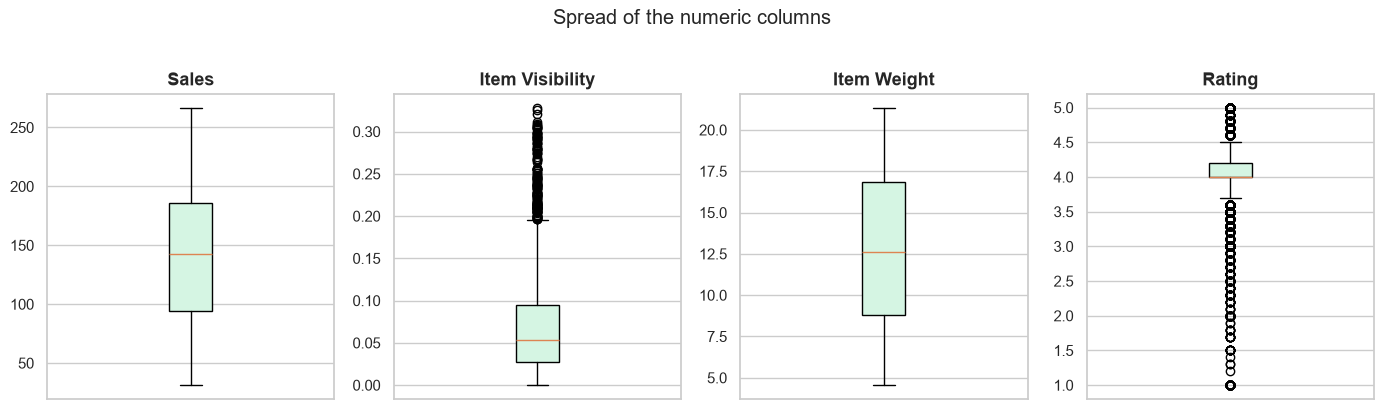

In [8]:
def iqr_bounds(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr


outlier_rows = []
for column in ["Sales", "Item Visibility", "Item Weight", "Rating"]:
    values = raw[column].dropna()
    low, high = iqr_bounds(values)
    flagged = (values < low) | (values > high)
    outlier_rows.append({
        "Column": column,
        "Lower_fence": round(low, 3),
        "Upper_fence": round(high, 3),
        "Flagged_rows": int(flagged.sum()),
        "Flagged_pct": round(flagged.mean() * 100, 2),
        "Observed_min": round(values.min(), 3),
        "Observed_max": round(values.max(), 3),
    })
display(pd.DataFrame(outlier_rows))

print(f"Records with item visibility exactly 0: {(raw['Item Visibility'] == 0).sum():,}")
print(f"Records with negative or zero sales: {((raw['Sales'] <= 0).sum()):,}")

fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, column in zip(axes, ["Sales", "Item Visibility", "Item Weight", "Rating"]):
    ax.boxplot(raw[column].dropna(), vert=True, patch_artist=True, boxprops={"facecolor": "#D5F5E3"})
    ax.set_title(column)
    ax.set_xticks([])
fig.suptitle("Spread of the numeric columns", y=1.02)
show_figure("06_outlier_boxplots")

How each flag is treated:

- **Sales.** No value sits outside the fences. The range 31 to 267 is kept in full.
- **Item Weight.** No extreme weights. The problem is missing weight, not odd weight.
- **Item Visibility.** 144 rows sit above the upper fence, and 526 rows are exactly 0. A visibility of 0 means the product was given no shelf share, which is not a usable display figure. Those zeros are treated as missing and filled from the same product's visibility at other outlets. The high-visibility rows are kept. They are uncommon, but a product can genuinely take a large share of a small shelf, especially in a grocery store.
- **Rating.** The middle half of ratings is squeezed between 4.0 and 4.2, so the fence calls 1,931 rows unusual even though scores from 1 to 5 are valid ratings. Those rows are kept. The 114 scores of exactly 1.0 are called out for a store check, because a perfect 1.0 is more likely a default or a serious complaint than a finely measured score.

### Task 2.4. Are similar facts written in the same way?

Fat content is stored as five strings for two groups. Outlet size is stored as three different sizes for three outlets. Both are standardized before the comparisons in Objective 3.

In [9]:
NON_EDIBLE = ["Household", "Health and Hygiene", "Others"]
FAT_MAP = {
    "LF": "Low Fat",
    "low fat": "Low Fat",
    "Low Fat": "Low Fat",
    "reg": "Regular",
    "Regular": "Regular",
}


def clean_blinkit(data):
    """Return a copy with consistent labels and filled measurement gaps."""
    clean = data.copy()

    clean["Item Fat Content"] = clean["Item Fat Content"].replace(FAT_MAP)
    clean["Item Category"] = np.where(
        clean["Item Type"].isin(NON_EDIBLE), "Non-Consumable", "Food"
    )
    # A fat label does not describe household or hygiene products.
    clean.loc[clean["Item Category"] == "Non-Consumable", "Item Fat Content"] = "Non-Edible"

    # Weight is constant for a product. Fill outlet gaps from that product's known weight.
    weight_by_item = clean.groupby("Item Identifier")["Item Weight"].transform("mean")
    clean["Item Weight"] = clean["Item Weight"].fillna(weight_by_item)
    weight_by_type = clean.groupby("Item Type")["Item Weight"].transform("mean")
    clean["Item Weight"] = clean["Item Weight"].fillna(weight_by_type)

    # A visibility of 0 is treated as an unrecorded shelf share.
    clean["Item Visibility"] = clean["Item Visibility"].mask(clean["Item Visibility"] == 0)
    vis_by_item = clean.groupby("Item Identifier")["Item Visibility"].transform("mean")
    clean["Item Visibility"] = clean["Item Visibility"].fillna(vis_by_item)
    vis_by_type = clean.groupby("Item Type")["Item Visibility"].transform("mean")
    clean["Item Visibility"] = clean["Item Visibility"].fillna(vis_by_type)

    # One size per outlet: the size recorded most often for that outlet.
    size_mode = clean.groupby("Outlet Identifier")["Outlet Size"].agg(lambda s: s.mode().iloc[0])
    clean["Outlet Size"] = clean["Outlet Identifier"].map(size_mode)
    clean["Outlet Size Reliable"] = clean["Outlet Identifier"].map(
        data.groupby("Outlet Identifier")["Outlet Size"].nunique().eq(1)
    )

    latest_year = int(clean["Outlet Establishment Year"].max())
    clean["Outlet Age"] = latest_year - clean["Outlet Establishment Year"]
    return clean


clean = clean_blinkit(raw)

print("Fat labels before and after standardization")
fat_compare = pd.DataFrame({
    "Before": raw["Item Fat Content"].value_counts(),
    "After": clean["Item Fat Content"].value_counts(),
}).fillna(0).astype(int)
display(fat_compare)

print("Missing values after cleaning")
display(clean.isna().sum().to_frame("Missing_rows"))

print("Outlet size used for each outlet, and whether the source file already agreed")
size_check = (
    clean.groupby("Outlet Identifier")
    .agg(
        Outlet_Type=("Outlet Type", "first"),
        Standardized_size=("Outlet Size", "first"),
        Size_was_consistent=("Outlet Size Reliable", "first"),
    )
)
display(size_check)

clean_path = Path("BlinkIT_Grocery_Data_Cleaned.xlsx")
clean.to_excel(clean_path, index=False)
print(f"Cleaned file written to {clean_path.resolve()}")

Fat labels before and after standardization


,Before,After
Item Fat Content,,
LF,316,0
Low Fat,5089,3918
Non-Edible,0,1599
Regular,2889,3006
low fat,112,0
reg,117,0


Missing values after cleaning


,Missing_rows
Item Fat Content,0
Item Identifier,0
Item Type,0
Outlet Establishment Year,0
Outlet Identifier,0
Outlet Location Type,0
Outlet Size,0
Outlet Type,0
Item Visibility,0
Item Weight,0


Outlet size used for each outlet, and whether the source file already agreed


,Outlet_Type,Standardized_size,Size_was_consistent
Outlet Identifier,,,
OUT010,Grocery Store,Medium,False
OUT013,Supermarket Type1,High,True
OUT017,Supermarket Type1,Small,False
OUT018,Supermarket Type2,Medium,True
OUT019,Grocery Store,Small,True
OUT027,Supermarket Type3,Medium,True
OUT035,Supermarket Type1,Small,True
OUT045,Supermarket Type1,Medium,False
OUT046,Supermarket Type1,Small,True


Cleaned file written to C:\Users\pradi\OneDrive\AI ML workspace\AI ML internship\Sapphire IQ\Blinkit Sales Analysis-20261028T051134Z-1-001\Blinkit Sales Analysis\BlinkIT_Grocery_Data_Cleaned.xlsx


What changed, and what did not:

- 545 fat labels (`LF`, `low fat`, `reg`) were mapped to Low Fat or Regular. Non-food rows are marked Non-Edible so they do not distort the fat comparison.
- 1,463 missing weights were filled from the same item. No item was left without a weight.
- 526 zero-visibility values were filled from the same item, then from the category if needed.
- Outlet size was set to the most common label inside each outlet. OUT010, OUT017, and OUT045 were inconsistent in the source file, so size comparisons later use only the seven outlets whose size never changed.
- No rows were deleted. There were no duplicate product-outlet records and no impossible sales values.

## Objective 3. Find out what is driving better sales performance

From here onward the charts use the cleaned file.

### Task 3.1. Which types of products are selling more?

Two different answers matter. **Total sales** shows which categories contribute the most money-value in this file. **Average sales** shows which categories carry a higher sales value on a typical item. A category can lead the total only because it has more listings.

,Listings,Total_sales,Average_sales,Average_rating,Sales_share_pct,Listing_share_pct,Sales_index
Item Type,,,,,,,
Fruits and Vegetables,1232,178124.08,144.58,3.96,14.82,14.46,1.03
Snack Foods,1200,175433.92,146.19,3.95,14.60,14.08,1.04
Household,910,135976.53,149.42,4.00,11.32,10.68,1.06
Frozen Foods,856,118558.88,138.50,3.97,9.87,10.04,0.98
Dairy,682,101276.46,148.50,3.97,8.43,8.00,1.05
Canned,649,90706.73,139.76,3.99,7.55,7.61,0.99
Baking Goods,648,81894.74,126.38,3.98,6.82,7.60,0.90
Health and Hygiene,520,68025.84,130.82,3.99,5.66,6.10,0.93
Meat,425,59449.86,139.88,4.02,4.95,4.99,0.99


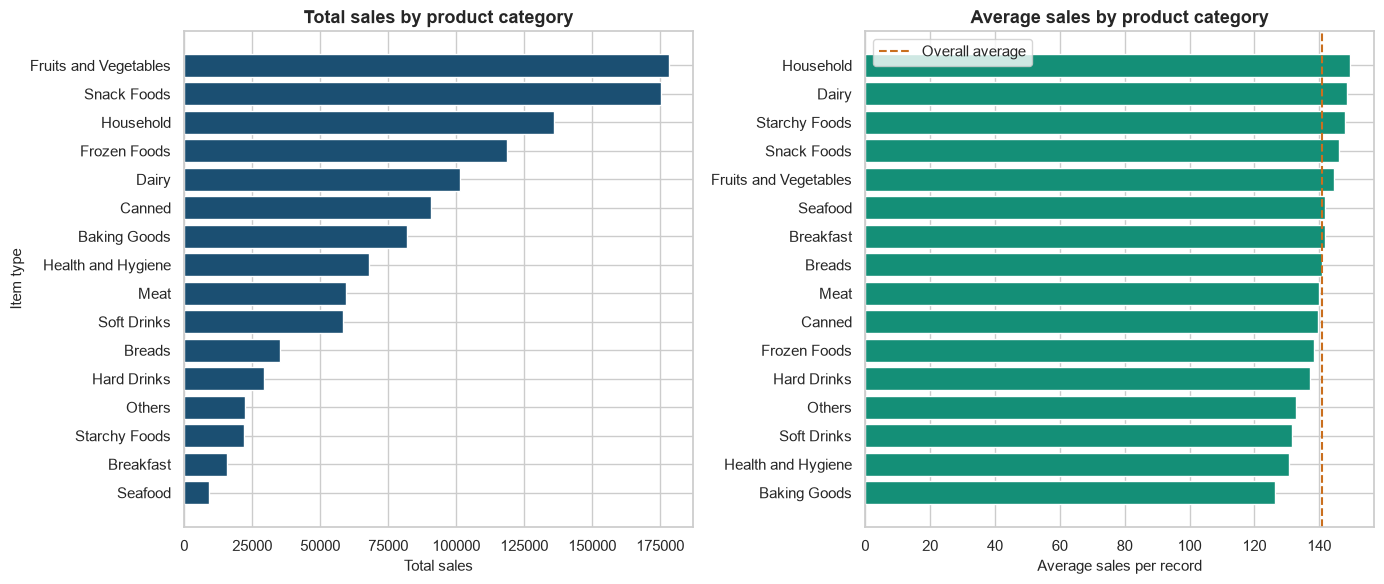

Edible products only: fat content versus sales


,Listings,Total_sales,Average_sales
Item Fat Content,,,
Low Fat,3918,549865.43,140.34
Regular,3006,425361.80,141.50


In [10]:
category = (
    clean.groupby("Item Type")
    .agg(
        Listings=("Sales", "size"),
        Total_sales=("Sales", "sum"),
        Average_sales=("Sales", "mean"),
        Average_rating=("Rating", "mean"),
    )
    .sort_values("Total_sales", ascending=False)
)
category["Sales_share_pct"] = category["Total_sales"] / category["Total_sales"].sum() * 100
category["Listing_share_pct"] = category["Listings"] / category["Listings"].sum() * 100
category["Sales_index"] = category["Sales_share_pct"] / category["Listing_share_pct"]
display(category.round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
by_total = category["Total_sales"].sort_values()
by_avg = category["Average_sales"].sort_values()
axes[0].barh(by_total.index, by_total.values, color="#1B4F72")
axes[0].set_title("Total sales by product category")
axes[0].set_xlabel("Total sales")
axes[0].set_ylabel("Item type")
axes[1].barh(by_avg.index, by_avg.values, color="#148F77")
axes[1].axvline(clean["Sales"].mean(), color="#CA6F1E", linestyle="--", label="Overall average")
axes[1].set_title("Average sales by product category")
axes[1].set_xlabel("Average sales per record")
axes[1].set_ylabel("")
axes[1].legend()
show_figure("07_sales_by_category")

print("Edible products only: fat content versus sales")
food = clean[clean["Item Category"] == "Food"]
fat_sales = (
    food.groupby("Item Fat Content")
    .agg(Listings=("Sales", "size"), Total_sales=("Sales", "sum"), Average_sales=("Sales", "mean"))
    .round(2)
)
display(fat_sales)

Fruits and Vegetables (14.8% of sales) and Snack Foods (14.6%) are the two largest contributors, followed by Household (11.3%). They lead because BlinkIT lists many of them, and their average sales also sit above the catalog average.

The higher sales value per item sits with Household (149), Dairy (148), Starchy Foods (148), and Snack Foods (146). Baking Goods is the weak spot: it is a large range (648 listings) but the lowest average sales (126). Health and Hygiene and Soft Drinks also sit below the catalog average.

Low Fat food items outnumber Regular items, but the average sales values are almost the same (about 140 versus 142). Fat content is not what separates stronger products from weaker ones. Starchy Foods is a small range with a high average, so it is a candidate to stock more widely. Baking Goods is a large range with a low average, so it is a candidate to review item by item.

### Task 3.2. Which types of outlets are performing better?

Performance is read two ways: total sales contributed by the outlet, and average sales per product listed there.

,,,,Listings,Total_sales,Average_sales,Average_rating,Average_visibility
Outlet Identifier,Outlet Type,Outlet Location Type,Outlet Establishment Year,,,,,
OUT035,Supermarket Type1,Tier 2,2017,930,133103.91,143.12,3.94,0.07
OUT046,Supermarket Type1,Tier 1,2016,930,132113.37,142.06,3.96,0.07
OUT013,Supermarket Type1,Tier 3,2014,932,131809.02,141.43,3.95,0.06
OUT018,Supermarket Type2,Tier 3,2022,928,131477.78,141.68,3.97,0.07
OUT045,Supermarket Type1,Tier 2,2015,929,130942.78,140.95,3.96,0.06
OUT027,Supermarket Type3,Tier 3,2018,935,130714.67,139.80,3.95,0.06
OUT049,Supermarket Type1,Tier 1,2012,930,130476.86,140.30,3.99,0.07
OUT017,Supermarket Type1,Tier 2,2020,926,129103.96,139.42,3.98,0.07
OUT010,Grocery Store,Tier 3,2011,555,78131.57,140.78,3.98,0.10


,Listings,Total_sales,Average_sales,Average_rating,Sales_share_pct
Outlet Type,,,,,
Supermarket Type1,5577,787549.89,141.21,3.96,65.54
Grocery Store,1083,151939.15,140.29,3.99,12.64
Supermarket Type2,928,131477.78,141.68,3.97,10.94
Supermarket Type3,935,130714.67,139.80,3.95,10.88


,Outlets,Listings,Total_sales,Average_sales,Sales_share_pct
Outlet Location Type,,,,,
Tier 1,3,2388,336397.81,140.87,27.99
Tier 2,3,2785,393150.65,141.17,32.72
Tier 3,4,3350,472133.03,140.94,39.29


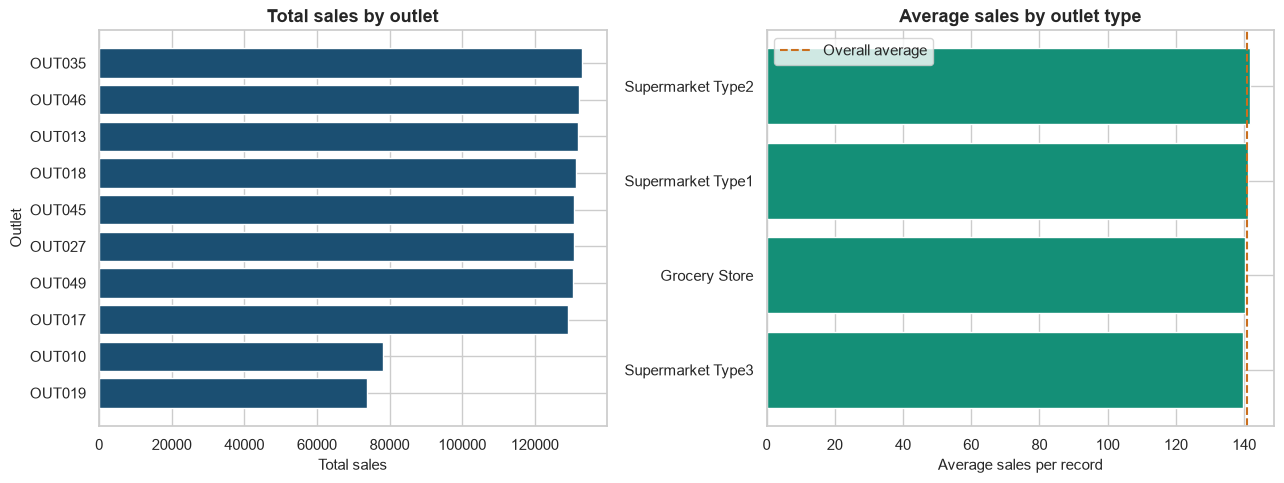

Outlet size compared only where every row for that outlet agreed on one size


,Outlets,Listings,Total_sales,Average_sales
Outlet Size,,,,
High,1,932,131809.02,141.43
Medium,3,2793,392669.31,140.59
Small,3,2388,339024.86,141.97


Supermarket Type1 only, and only outlets with a reliable size


,Outlets,Average_sales,Total_sales
Outlet Size,,,
High,1,141.43,131809.02
Medium,1,140.30,130476.86
Small,2,142.59,265217.28


In [11]:
outlet = (
    clean.groupby(["Outlet Identifier", "Outlet Type", "Outlet Location Type", "Outlet Establishment Year"])
    .agg(
        Listings=("Sales", "size"),
        Total_sales=("Sales", "sum"),
        Average_sales=("Sales", "mean"),
        Average_rating=("Rating", "mean"),
        Average_visibility=("Item Visibility", "mean"),
    )
    .sort_values("Total_sales", ascending=False)
)
display(outlet.round(2))

by_type = (
    clean.groupby("Outlet Type")
    .agg(Listings=("Sales", "size"), Total_sales=("Sales", "sum"), Average_sales=("Sales", "mean"), Average_rating=("Rating", "mean"))
    .sort_values("Total_sales", ascending=False)
)
by_type["Sales_share_pct"] = by_type["Total_sales"] / by_type["Total_sales"].sum() * 100
display(by_type.round(2))

by_location = (
    clean.groupby("Outlet Location Type")
    .agg(Outlets=("Outlet Identifier", "nunique"), Listings=("Sales", "size"), Total_sales=("Sales", "sum"), Average_sales=("Sales", "mean"))
    .sort_index()
)
by_location["Sales_share_pct"] = by_location["Total_sales"] / by_location["Total_sales"].sum() * 100
display(by_location.round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
outlet_plot = outlet.reset_index().sort_values("Total_sales")
axes[0].barh(outlet_plot["Outlet Identifier"], outlet_plot["Total_sales"], color="#1B4F72")
axes[0].set_title("Total sales by outlet")
axes[0].set_xlabel("Total sales")
axes[0].set_ylabel("Outlet")
type_order = by_type.sort_values("Average_sales")
axes[1].barh(type_order.index, type_order["Average_sales"], color="#148F77")
axes[1].axvline(clean["Sales"].mean(), color="#CA6F1E", linestyle="--", label="Overall average")
axes[1].set_title("Average sales by outlet type")
axes[1].set_xlabel("Average sales per record")
axes[1].legend()
show_figure("08_sales_by_outlet")

print("Outlet size compared only where every row for that outlet agreed on one size")
reliable = clean[clean["Outlet Size Reliable"]]
by_size = (
    reliable.groupby("Outlet Size")
    .agg(Outlets=("Outlet Identifier", "nunique"), Listings=("Sales", "size"), Total_sales=("Sales", "sum"), Average_sales=("Sales", "mean"))
)
display(by_size.round(2))

print("Supermarket Type1 only, and only outlets with a reliable size")
type1_size = (
    reliable[reliable["Outlet Type"] == "Supermarket Type1"]
    .groupby("Outlet Size")
    .agg(Outlets=("Outlet Identifier", "nunique"), Average_sales=("Sales", "mean"), Total_sales=("Sales", "sum"))
)
display(type1_size.round(2))

Supermarket Type1 contributes about 65.5% of sales because six of the ten outlets use that format and each lists roughly 930 products. The two grocery stores, OUT010 and OUT019, contribute about 12.6% together. Each grocery store lists roughly 530 to 555 products.

Average sales per product is about 140 at every format, every tier, and every establishment year. OUT035 is first on total sales (133,104) and OUT019 is last (73,808). The gap is the length of the catalog, not a higher sales value per product. Tier 3 leads total sales (39.3%) because more outlets sit there, not because a Tier 3 customer spends more per item.

Among Supermarket Type1 outlets whose size label is trustworthy, Small outlets (OUT035, OUT046) have a slightly higher average than the High outlet (OUT013) and the Medium outlet (OUT049). The difference is about 2 sales units. Outlet size is not a useful explanation of sales in this file.

### Task 3.3. Are visibility, weight, ratings, and outlet characteristics connected with sales?

The check is the correlation between each numeric characteristic and Sales, plus the average sales inside bands of visibility, weight, and rating.

,Item Visibility,Item Weight,Rating,Outlet Age,Outlet Establishment Year,Sales
Item Visibility,1.000,-0.021,-0.004,0.058,-0.058,-0.006
Item Weight,-0.021,1.000,0.004,0.002,-0.002,0.026
Rating,-0.004,0.004,1.000,-0.000,0.000,0.011
Outlet Age,0.058,0.002,-0.000,1.000,-1.000,0.001
Outlet Establishment Year,-0.058,-0.002,0.000,-1.000,1.000,-0.001
Sales,-0.006,0.026,0.011,0.001,-0.001,1.000


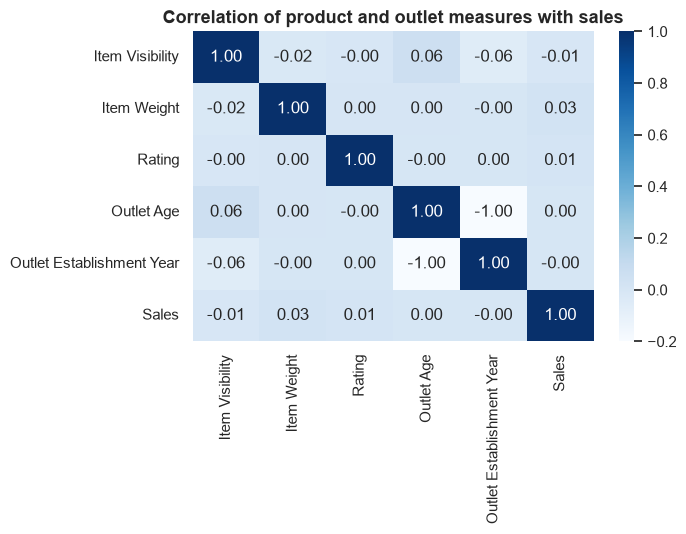

Sales by visibility band


,Records,Average_sales,Average_rating
Visibility band,,,
Q1 lowest visibility,2131,141.04,3.98
Q2,2131,137.16,3.96
Q3,2130,148.39,3.95
Q4 highest visibility,2131,137.38,3.97


Sales by weight band


,Records,Average_sales,Average_rating
Weight band,,,
Q1 lightest,2136,137.76,3.95
Q2,2169,141.40,3.98
Q3,2101,139.38,3.97
Q4 heaviest,2117,145.44,3.96


Sales by rating band


,Records,Average_sales,Average_rating
Rating band,,,
1 to 2,218,134.35,1.42
2 to 3,399,141.52,2.79
3 to 4,4734,141.97,3.89
4 to 5,3172,139.92,4.40


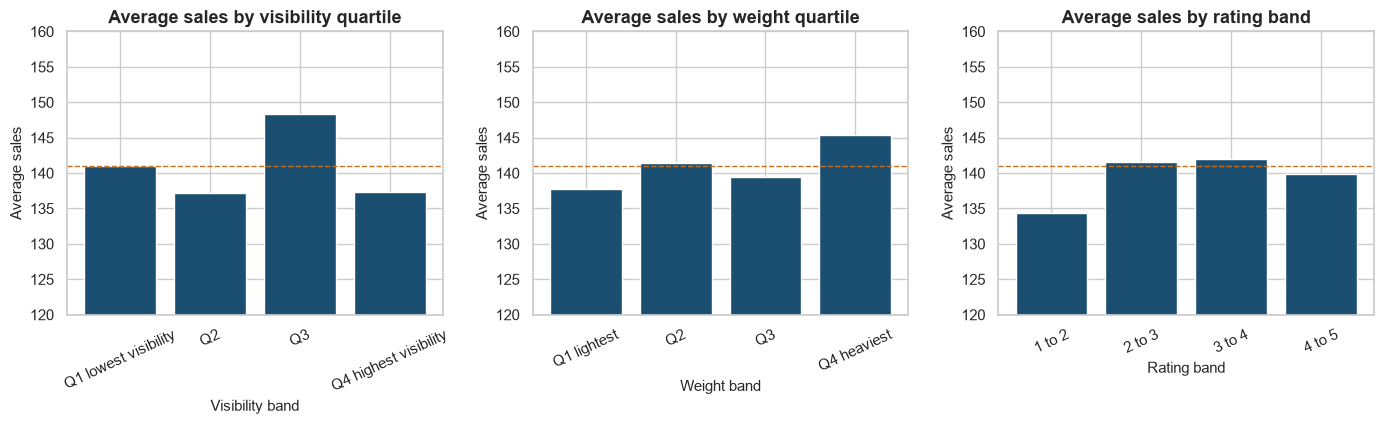

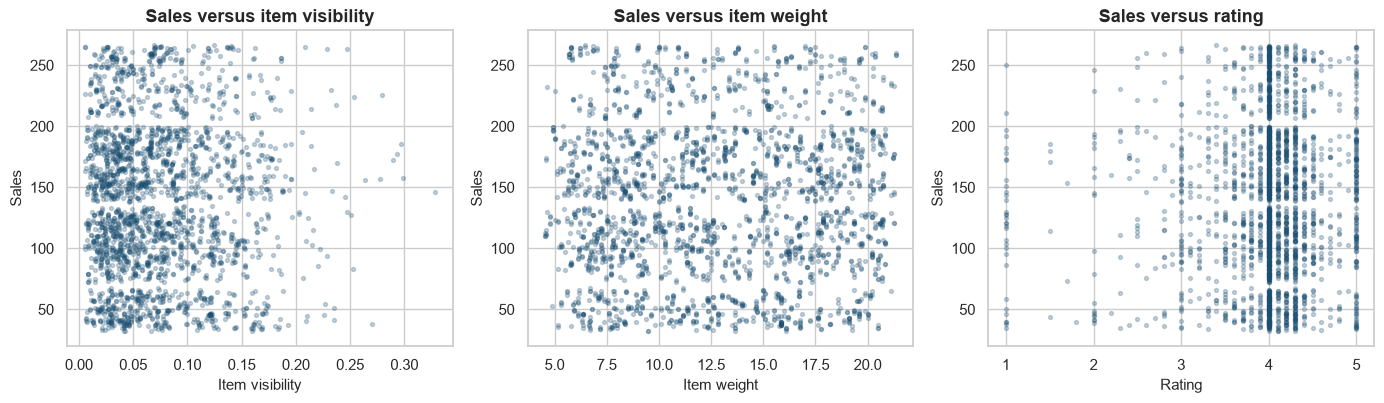

In [12]:
features = ["Item Visibility", "Item Weight", "Rating", "Outlet Age", "Outlet Establishment Year", "Sales"]
correlation = clean[features].corr()
display(correlation.round(3))

fig, ax = plt.subplots(figsize=(7.2, 5.5))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="Blues", vmin=-0.2, vmax=1, ax=ax)
ax.set_title("Correlation of product and outlet measures with sales")
show_figure("09_correlation_heatmap")

banded = clean.copy()
banded["Visibility band"] = pd.qcut(
    banded["Item Visibility"], 4, labels=["Q1 lowest visibility", "Q2", "Q3", "Q4 highest visibility"]
)
banded["Weight band"] = pd.qcut(
    banded["Item Weight"], 4, labels=["Q1 lightest", "Q2", "Q3", "Q4 heaviest"]
)
banded["Rating band"] = pd.cut(
    banded["Rating"], bins=[0, 2, 3, 4, 5], labels=["1 to 2", "2 to 3", "3 to 4", "4 to 5"]
)

def band_table(frame, column):
    table = (
        frame.groupby(column, observed=True)
        .agg(Records=("Sales", "size"), Average_sales=("Sales", "mean"), Average_rating=("Rating", "mean"))
        .round(2)
    )
    return table

print("Sales by visibility band")
display(band_table(banded, "Visibility band"))
print("Sales by weight band")
display(band_table(banded, "Weight band"))
print("Sales by rating band")
display(band_table(banded, "Rating band"))

fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
for ax, column, title in zip(
    axes,
    ["Visibility band", "Weight band", "Rating band"],
    ["Average sales by visibility quartile", "Average sales by weight quartile", "Average sales by rating band"],
):
    table = band_table(banded, column)
    ax.bar(table.index.astype(str), table["Average_sales"], color="#1B4F72")
    ax.axhline(clean["Sales"].mean(), color="#CA6F1E", linestyle="--", linewidth=1)
    ax.set_title(title)
    ax.set_xlabel(column)
    ax.set_ylabel("Average sales")
    ax.tick_params(axis="x", rotation=25)
    ax.set_ylim(120, 160)
show_figure("10_sales_by_feature_bands")

sample = clean.sample(n=min(2500, len(clean)), random_state=42)
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, column, label in zip(
    axes,
    ["Item Visibility", "Item Weight", "Rating"],
    ["Item visibility", "Item weight", "Rating"],
):
    ax.scatter(sample[column], sample["Sales"], s=8, alpha=0.25, color="#1B4F72")
    ax.set_title(f"Sales versus {label.lower()}")
    ax.set_xlabel(label)
    ax.set_ylabel("Sales")
show_figure("11_sales_scatter")

None of the measured characteristics has a meaningful linear link with sales:

- Visibility and sales: correlation about 0.00. The highest-visibility quarter does not sell more.
- Weight and sales: correlation about 0.03. The heaviest quarter averages about 146, against about 138 for the lightest quarter. That is a small tilt, not a planning rule.
- Rating and sales: correlation about 0.01. Records rated 4 to 5 do not outsell records rated 3 to 4. The small group rated 1 to 2 averages about 134, a little under the catalog, but rating will not forecast sales.
- Outlet age and sales: correlation about 0.00. Newer outlets do not show a higher sales value per product.

Grocery stores do show higher average visibility than supermarkets, because each product takes a larger share of a smaller shelf. That extra visibility does not come with a higher sales value. Visibility is a description of the shelf, not a driver of the Sales column in this file.

### Task 3.4. How do stronger products and outlets differ from weaker ones?

A product is included in this comparison when it is listed at 3 or more outlets, so a single odd row does not define it. Strong products are the top 20% by average sales. Weak products are the bottom 20%.

,Products,Average_sales,Average_rating,Average_visibility,Average_weight,Average_listings
Performance,,,,,,
Strong (top 20%),303,230.56,3.97,0.07,12.97,5.58
Weak (bottom 20%),303,55.42,3.96,0.07,12.71,5.58


Strong-product cutoff (average sales): 194.16
Weak-product cutoff (average sales): 84.81


,Performance,Item_Type,Products,Share_within_group_pct
13,Strong (top 20%),Snack Foods,46,15.18
6,Strong (top 20%),Fruits and Vegetables,44,14.52
4,Strong (top 20%),Dairy,37,12.21
9,Strong (top 20%),Household,37,12.21
5,Strong (top 20%),Frozen Foods,32,10.56
21,Weak (bottom 20%),Frozen Foods,40,13.20
22,Weak (bottom 20%),Fruits and Vegetables,37,12.21
29,Weak (bottom 20%),Snack Foods,32,10.56
16,Weak (bottom 20%),Baking Goods,29,9.57
20,Weak (bottom 20%),Dairy,28,9.24


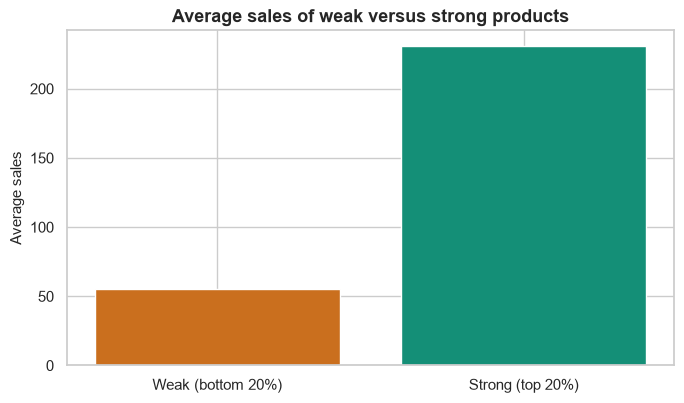

Three highest outlets by total sales


,Outlet Identifier,Outlet Type,Outlet Location Type,Listings,Total_sales,Average_sales
0,OUT035,Supermarket Type1,Tier 2,930,133103.91,143.12
1,OUT046,Supermarket Type1,Tier 1,930,132113.37,142.06
2,OUT013,Supermarket Type1,Tier 3,932,131809.02,141.43


Three lowest outlets by total sales


,Outlet Identifier,Outlet Type,Outlet Location Type,Listings,Total_sales,Average_sales
7,OUT017,Supermarket Type1,Tier 2,926,129103.96,139.42
8,OUT010,Grocery Store,Tier 3,555,78131.57,140.78
9,OUT019,Grocery Store,Tier 1,528,73807.58,139.79


In [13]:
product = (
    clean.groupby("Item Identifier")
    .agg(
        Listings=("Sales", "size"),
        Average_sales=("Sales", "mean"),
        Total_sales=("Sales", "sum"),
        Average_rating=("Rating", "mean"),
        Average_visibility=("Item Visibility", "mean"),
        Average_weight=("Item Weight", "mean"),
        Item_Type=("Item Type", "first"),
        Fat=("Item Fat Content", "first"),
        Category=("Item Category", "first"),
    )
)
eligible = product[product["Listings"] >= 3].copy()
high_cut = eligible["Average_sales"].quantile(0.80)
low_cut = eligible["Average_sales"].quantile(0.20)
eligible["Performance"] = np.where(
    eligible["Average_sales"] >= high_cut,
    "Strong (top 20%)",
    np.where(eligible["Average_sales"] <= low_cut, "Weak (bottom 20%)", "Middle"),
)
compare = (
    eligible[eligible["Performance"] != "Middle"]
    .groupby("Performance")
    .agg(
        Products=("Average_sales", "size"),
        Average_sales=("Average_sales", "mean"),
        Average_rating=("Average_rating", "mean"),
        Average_visibility=("Average_visibility", "mean"),
        Average_weight=("Average_weight", "mean"),
        Average_listings=("Listings", "mean"),
    )
    .round(2)
)
display(compare)

print(f"Strong-product cutoff (average sales): {high_cut:.2f}")
print(f"Weak-product cutoff (average sales): {low_cut:.2f}")

mix = (
    eligible[eligible["Performance"] != "Middle"]
    .groupby(["Performance", "Item_Type"])
    .size()
    .rename("Products")
    .reset_index()
)
mix["Share_within_group_pct"] = mix.groupby("Performance")["Products"].transform(lambda s: s / s.sum() * 100)
top_mix = (
    mix.sort_values(["Performance", "Products"], ascending=[True, False])
    .groupby("Performance")
    .head(5)
)
display(top_mix.round(2))

fig, ax = plt.subplots(figsize=(7, 4.2))
plot_compare = compare.loc[["Weak (bottom 20%)", "Strong (top 20%)"], "Average_sales"]
ax.bar(plot_compare.index, plot_compare.values, color=["#CA6F1E", "#148F77"])
ax.set_title("Average sales of weak versus strong products")
ax.set_ylabel("Average sales")
ax.set_xlabel("")
show_figure("12_strong_vs_weak_products")

outlet_rank = outlet.reset_index()
best_outlets = outlet_rank.head(3)[["Outlet Identifier", "Outlet Type", "Outlet Location Type", "Listings", "Total_sales", "Average_sales"]]
weak_outlets = outlet_rank.tail(3)[["Outlet Identifier", "Outlet Type", "Outlet Location Type", "Listings", "Total_sales", "Average_sales"]]
print("Three highest outlets by total sales")
display(best_outlets.round(2))
print("Three lowest outlets by total sales")
display(weak_outlets.round(2))

Strong products average about 231 in sales. Weak products average about 55. That gap is the product's own sales value. It is not explained by rating, visibility, or weight: those three averages are nearly identical in the two groups. Strong and weak products also show up inside the same large categories (Snack Foods, Fruits and Vegetables, Frozen Foods, Dairy, Household). The category sets the range, and the individual product decides whether the value is high or low.

On outlets, the top of the table is a block of supermarkets with about 930 listings and about 130,000 to 133,000 in total sales. The bottom is the two grocery stores, with about 40% fewer listings and about 74,000 to 78,000 in total sales. Their average sales per product matches the supermarkets. The operating difference is assortment depth.

## Objective 4. Help management make better business decisions

### Task 4.1. Which products contribute more to sales?

Contribution is the sum of Sales across every outlet that lists the product. The catalog is wide: the top 10 products are only a small slice of total sales, so the business is not dependent on a handful of hero SKUs. The products below are still the ones to protect, because each combines a high sales value with a listing at most outlets.

,Item Identifier,Item_Type,Listings,Average_sales,Total_sales,Average_rating,Cumulative_share_pct
0,FDU12,Baking Goods,9,263.45,2371.01,4.14,0.20
1,FDT07,Fruits and Vegetables,9,256.32,2306.90,4.00,0.39
2,NCQ06,Household,9,254.97,2294.71,4.12,0.58
3,FDL58,Snack Foods,8,263.96,2111.65,3.86,0.76
4,NCB31,Household,8,263.09,2104.73,3.84,0.93
5,FDX31,Fruits and Vegetables,9,233.83,2104.46,4.06,1.11
6,FDF05,Frozen Foods,8,262.89,2103.13,3.90,1.28
7,FDR59,Breads,8,262.07,2096.58,3.79,1.46
8,FDP28,Frozen Foods,8,260.98,2087.85,4.21,1.63
9,FDA04,Frozen Foods,8,259.01,2072.07,4.15,1.80


Products needed to reach 50% of sales: 467 of 1,559
Share of sales from the top 15 products: 2.7%


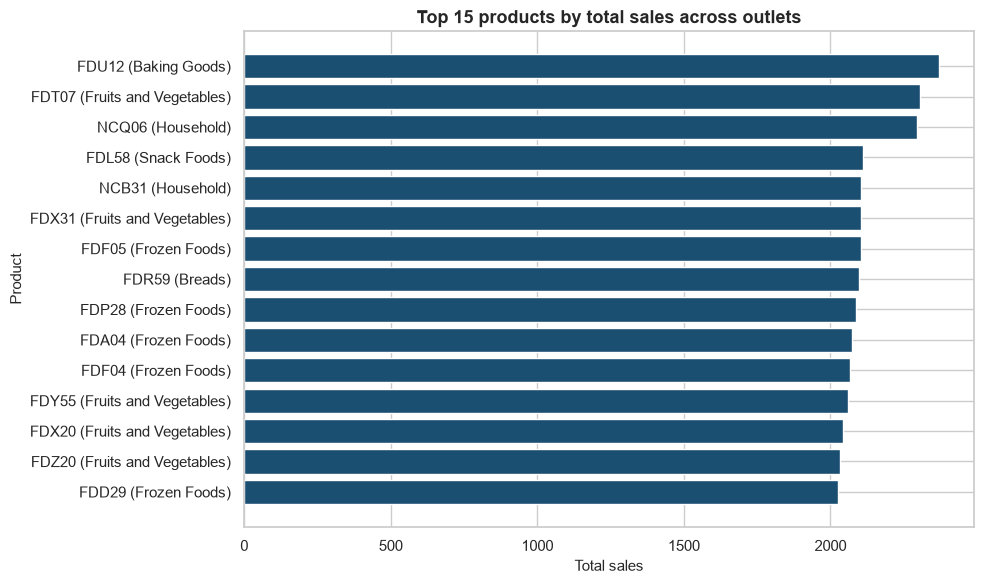

In [14]:
product_sales = product.sort_values("Total_sales", ascending=False).copy()
product_sales["Cumulative_share_pct"] = product_sales["Total_sales"].cumsum() / product_sales["Total_sales"].sum() * 100
top15 = product_sales.head(15).reset_index()
display(top15[["Item Identifier", "Item_Type", "Listings", "Average_sales", "Total_sales", "Average_rating", "Cumulative_share_pct"]].round(2))

n_for_half = int((product_sales["Cumulative_share_pct"] <= 50).sum()) + 1
print(f"Products needed to reach 50% of sales: {n_for_half:,} of {len(product_sales):,}")
print(f"Share of sales from the top 15 products: {product_sales.head(15)['Total_sales'].sum() / product_sales['Total_sales'].sum():.1%}")

fig, ax = plt.subplots(figsize=(10, 6))
labels = top15["Item Identifier"] + " (" + top15["Item_Type"] + ")"
ax.barh(labels[::-1], top15["Total_sales"][::-1], color="#1B4F72")
ax.set_title("Top 15 products by total sales across outlets")
ax.set_xlabel("Total sales")
ax.set_ylabel("Product")
show_figure("13_top_products")

### Task 4.2. Which outlets and locations are performing better?

OUT035 (Supermarket Type1, Tier 2, opened 2017) is the strongest outlet on total sales, with OUT046 and OUT013 close behind. All three list about 930 products. Tier 2 and the Supermarket Type1 format are the core of the network. Tier 3 produces the most sales in total only because it contains four outlets, including the grocery store OUT010, which pulls the tier's average down in contribution per outlet.

Listings  \
Outlet Location Type Outlet Identifier Outlet Type                   
Tier 1               OUT046            Supermarket Type1       930   
                     OUT049            Supermarket Type1       930   
                     OUT019            Grocery Store           528   
Tier 2               OUT035            Supermarket Type1       930   
                     OUT045            Supermarket Type1       929   
                     OUT017            Supermarket Type1       926   
Tier 3               OUT013            Supermarket Type1       932   
                     OUT018            Supermarket Type2       928   
                     OUT027            Supermarket Type3       935   
                     OUT010            Grocery Store           555   

                                                          Total_sales  \
Outlet Location Type Outlet Identifier Outlet Type                      
Tier 1               OUT046            Supermarket Type1    132113.37   
                     OUT049            Supermarket Type1    130476.86   
                     OUT019            Grocery Store         73807.58   
Tier 2               OUT035            Supermarket Type1    133103.91   
                     OUT045            Supermarket Type1    130942.78   
                     OUT017            Supermarket Type1    129103.96   
Tier 3               OUT013            Supermarket Type1    131809.02   
                     OUT018            Supermarket Type2    131477.78   
                     OUT027            Supermarket Type3    130714.67   
                     OUT010            Grocery Store         78131.57   

                                                          Average_sales  
Outlet Location Type Outlet Identifier Outlet Type                       
Tier 1               OUT046            Supermarket Type1         142.06  
                     OUT049            Supermarket Type1         140.30  
                     OUT019            Grocery Store             139.79  
Tier 2               OUT035            Supermarket Type1         143.12  
                     OUT045            Supermarket Type1         140.95  
                     OUT017            Supermarket Type1         139.42  
Tier 3               OUT013            Supermarket Type1         141.43  
                     OUT018            Supermarket Type2         141.68  
                     OUT027            Supermarket Type3         139.80  
                     OUT010            Grocery Store             140.78

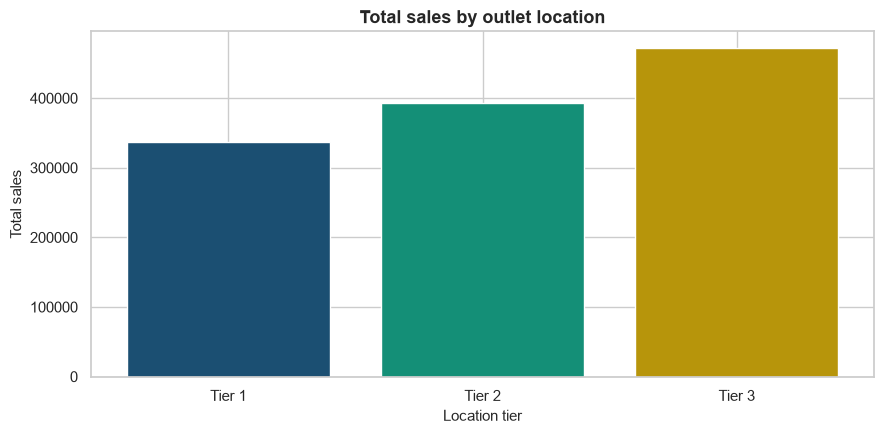

In [15]:
location_outlet = (
    clean.groupby(["Outlet Location Type", "Outlet Identifier", "Outlet Type"])
    .agg(Listings=("Sales", "size"), Total_sales=("Sales", "sum"), Average_sales=("Sales", "mean"))
    .sort_values(["Outlet Location Type", "Total_sales"], ascending=[True, False])
    .round(2)
)
display(location_outlet)

fig, ax = plt.subplots(figsize=(9, 4.5))
loc_sales = clean.groupby("Outlet Location Type")["Sales"].sum().sort_index()
ax.bar(loc_sales.index, loc_sales.values, color=["#1B4F72", "#148F77", "#B7950B"])
ax.set_title("Total sales by outlet location")
ax.set_xlabel("Location tier")
ax.set_ylabel("Total sales")
show_figure("14_sales_by_location")

### Task 4.3. Where can performance improve?

The shortfalls below are the places where the current pattern leaves sales on the table. They come from the category averages, the outlet catalog sizes, and the data gaps that still limit a size comparison.

In [16]:
overall_avg = clean["Sales"].mean()
category_gap = category.copy()
category_gap["Gap_vs_average"] = category_gap["Average_sales"] - overall_avg
weak_categories = category_gap.sort_values("Gap_vs_average").head(5)[
    ["Listings", "Average_sales", "Total_sales", "Sales_share_pct", "Gap_vs_average"]
]
print("Categories with the lowest average sales")
display(weak_categories.round(2))

small_strong = category_gap.sort_values("Average_sales", ascending=False)
small_strong = small_strong[small_strong["Listings"] < 250][
    ["Listings", "Average_sales", "Total_sales", "Sales_share_pct"]
]
print("Small categories whose average sales are relatively high")
display(small_strong.round(2))

grocery = clean[clean["Outlet Type"] == "Grocery Store"]
supermarket = clean[clean["Outlet Type"].str.startswith("Supermarket")]
coverage = pd.DataFrame({
    "Format": ["Grocery Store", "Supermarket"],
    "Outlets": [grocery["Outlet Identifier"].nunique(), supermarket["Outlet Identifier"].nunique()],
    "Average listings per outlet": [
        grocery.groupby("Outlet Identifier").size().mean(),
        supermarket.groupby("Outlet Identifier").size().mean(),
    ],
    "Average sales per record": [grocery["Sales"].mean(), supermarket["Sales"].mean()],
    "Total sales": [grocery["Sales"].sum(), supermarket["Sales"].sum()],
}).round(2)
display(coverage)

low_rated = clean[clean["Rating"] <= 2]
print(f"Records rated 2 or below: {len(low_rated):,} ({len(low_rated) / len(clean):.1%} of the file)")
print(f"Of which rated exactly 1.0: {(clean['Rating'] == 1).sum():,}")
print("These low scores are spread across outlets, so they are not one store's problem.")
display(low_rated.groupby("Outlet Identifier").size().rename("Records_rated_2_or_below").to_frame())

Categories with the lowest average sales


,Listings,Average_sales,Total_sales,Sales_share_pct,Gap_vs_average
Item Type,,,,,
Baking Goods,648,126.38,81894.74,6.82,-14.61
Health and Hygiene,520,130.82,68025.84,5.66,-10.17
Soft Drinks,445,131.49,58514.17,4.87,-9.50
Others,169,132.85,22451.89,1.87,-8.14
Hard Drinks,214,137.08,29334.68,2.44,-3.91


Small categories whose average sales are relatively high


,Listings,Average_sales,Total_sales,Sales_share_pct
Item Type,,,,
Starchy Foods,148,147.84,21880.03,1.82
Seafood,64,141.84,9077.87,0.76
Breakfast,110,141.79,15596.70,1.30
Hard Drinks,214,137.08,29334.68,2.44
Others,169,132.85,22451.89,1.87


,Format,Outlets,Average listings per outlet,Average sales per record,Total sales
0,Grocery Store,2,541.5,140.29,151939.15
1,Supermarket,8,930.0,141.09,1049742.34


Records rated 2 or below: 218 (2.6% of the file)
Of which rated exactly 1.0: 114
These low scores are spread across outlets, so they are not one store's problem.


,Records_rated_2_or_below
Outlet Identifier,
OUT010,21
OUT013,20
OUT017,22
OUT018,21
OUT019,10
OUT027,22
OUT035,33
OUT045,24
OUT046,27


### Task 4.4. Practical suggestions

The suggestions below are limited to patterns that the cleaned data actually supports.

**1. Grow the grocery catalogs toward the supermarket listing count.**
OUT010 and OUT019 each carry about 530 to 555 products, against about 930 at a supermarket. Average sales per product is the same. Closing even part of that assortment gap is the largest outlet-level opportunity in the file. Start with products that already sell above the catalog average and that are listed in most supermarkets but missing from the grocery stores.

**2. Protect the three categories that already carry the business.**
Fruits and Vegetables, Snack Foods, and Household together account for about 41% of sales. Keep the high-value items in these categories listed at every outlet. The strongest individual products (for example FDU12, FDT07, and NCQ06) are already in 8 or 9 outlets and have average sales above 250. A stock-out of these items at a grocery store costs more than a stock-out of a low-value baking item.

**3. Review Baking Goods item by item, and test a wider Starchy Foods range.**
Baking Goods has 648 listings but the lowest average sales in the catalog (about 126, against an overall average of 141). Identify the bottom of that range and drop or reprice the weak items rather than adding more of the same. Starchy Foods is the opposite case: few listings (148) and a high average (about 148). A wider starchy range is a better expansion bet than more baking SKUs. Dairy is a second expansion candidate: high average, mid-sized range.

**4. Do not use fat content, shelf visibility, outlet size, or rating as a sales lever.**
After the labels were standardized, Regular food items sell at essentially the same average as Low Fat items. Visibility and rating have correlations with sales of about zero. Outlet size, once limited to outlets with a consistent label, shifts average sales by only about 2 units. Money spent chasing a low-fat badge, a bigger shelf tag, or a larger store format will not move this sales figure. Use rating for quality follow-up only.

**5. Check every product-outlet row rated 1.0.**
There are 114 such rows, spread across all 10 outlets, and their average sales (about 131) is a little below the catalog. Confirm whether the score is a real complaint or a default value. If the complaints are real, they are a service problem. If they are defaults, the rating field should be repaired before it is used in any later model.

**6. Keep the data rules from Objective 2 in the reporting pipeline.**
Standardize fat labels on ingest. Fill item weight from the product master when an outlet file arrives blank, which is what happened for OUT019 and OUT027. Reject a visibility of 0, or store it as unknown. Store one outlet size on the outlet master. OUT010, OUT017, and OUT045 still need a confirmed size from operations before any size-based decision is made.

**What this file cannot answer.** Sales on a product changes by only a few units from outlet to outlet, and there is no quantity or transaction-count column. The analysis can rank products, categories, and catalog depth. It cannot say how many units moved, or whether a promotion increased demand. A later extract with units sold and number of orders would be needed before pricing or promotion decisions.

## Checkpoint summary

In [17]:
checkpoints = pd.DataFrame({
    "Objective": [
        "1. Understand the business",
        "2. Make the information reliable",
        "3. Find what drives sales",
        "4. Decide what to do",
    ],
    "Result": [
        "16 categories, 1,559 products, 10 outlets. Total sales "
        f"{clean['Sales'].sum():,.0f}. Average rating {clean['Rating'].mean():.2f}.",
        "No duplicate product-outlet rows. Weight was blank at two outlets, "
        "fat labels were inconsistent, three outlets had conflicting sizes, "
        "and 526 visibility values were zero. Those issues are corrected in the cleaned file.",
        "Category and the product's own sales value drive the numbers. "
        "Visibility, weight, rating, fat content, outlet type, tier, and store age do not.",
        "Deepen grocery assortments, defend F&V, snacks, and household, "
        "trim weak baking items, expand starchy foods, and repair ratings of 1.0.",
    ],
})
display(checkpoints)
print("Cleaned analysis file: BlinkIT_Grocery_Data_Cleaned.xlsx")
print("Figures saved in the figures folder.")

,Objective,Result
0,1. Understand the business,"16 categories, 1,559 products, 10 outlets. Tot..."
1,2. Make the information reliable,No duplicate product-outlet rows. Weight was b...
2,3. Find what drives sales,Category and the product's own sales value dri...
3,4. Decide what to do,"Deepen grocery assortments, defend F&V, snacks..."


Cleaned analysis file: BlinkIT_Grocery_Data_Cleaned.xlsx
Figures saved in the figures folder.
